## Imports

In [69]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV

## Data preparation

### Loading the data
Link to the dataset: https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset?resource=download

In [70]:
df=pd.read_csv('Student_Depression_Dataset.csv')

In [71]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


### Making everything uniform

In [72]:
df.columns=df.columns.str.lower()

In [73]:
str_columns=list(df.dtypes[df.dtypes=='str'].index)

In [74]:
for c in str_columns:
    df[c]=df[c].str.lower().str.replace(' ', '_')

In [75]:
df.depression=(df.depression=='yes').astype(int)

In [76]:
df.head()

,gender,age,family_background,relationship_status,marital_status,living_style,current_semester,cgpa,friend_circle,health_condition,cost_without_study,home_division,depression
0,female,22,middle_class,single,unmarried,bachelor,8,3.43,yes,critical,10113,chittagong,1
1,male,19,middle_class,single,unmarried,bachelor,2,3.70,yes,abnormal,13815,chittagong,1
2,male,23,middle_class,single,unmarried,family,8,3.28,no,abnormal,15450,dhaka,1
3,male,20,middle_class,complicated,unmarried,family,2,3.77,no,good,17413,dhaka,0
4,female,21,middle_class,single,unmarried,family,1,4.00,no,abnormal,16693,dhaka,1


### Splitting the data

In [77]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df_train), len(df_val), len(df_test)

(2678, 893, 893)

In [78]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [79]:
y_train = df_train.depression.values
y_val = df_val.depression.values
y_test = df_test.depression.values

In [80]:
del df_train['depression']
del df_val['depression']
del df_test['depression']

## EDA

In [81]:
df_full_train.describe()

,age,current_semester,cgpa,cost_without_study,depression
count,3571.000000,3571.000000,3571.000000,3571.000000,3571.000000
mean,22.632036,5.411929,3.413167,11254.558107,0.263232
std,2.036123,2.595679,0.387100,6656.160237,0.440449
min,17.000000,0.000000,2.250000,0.000000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000,0.000000
50%,23.000000,5.000000,3.490000,9500.000000,0.000000
75%,24.000000,7.000000,3.700000,15568.000000,1.000000
max,28.000000,12.000000,4.000000,32000.000000,1.000000


In [82]:
#checking for null values
df_full_train.isnull().sum()

gender                 0
age                    0
family_background      0
relationship_status    0
marital_status         0
living_style           0
current_semester       0
cgpa                   0
friend_circle          0
health_condition       0
cost_without_study     0
home_division          0
depression             0
dtype: int64

In [83]:
#checking for duplicates
df_full_train.duplicated().sum()

np.int64(0)

The dataset doesn't have any missing values or duplicates

In [84]:
df_full_train.depression.mean()

np.float64(0.26323158779053485)

Around 26% of the students in the dataset are classified with depression

In [85]:
numerical=['age', 'cgpa', 'cost_without_study']
categorical=[
       'gender', 
       'family_background', 
       'relationship_status',
       'marital_status',
       'living_style', 
       'current_semester',
       'friend_circle', 
       'health_condition',
       'home_division'
       ]

In [86]:
df_full_train[categorical].nunique()

gender                  2
family_background       3
relationship_status     3
marital_status          3
living_style            2
current_semester       13
friend_circle           2
health_condition        4
home_division           8
dtype: int64

### Analysing the numerical features

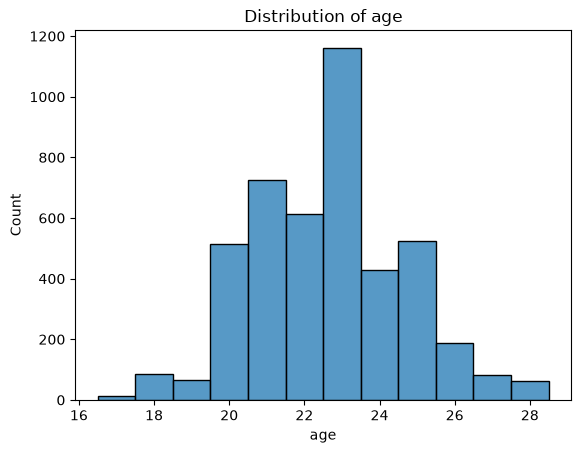

In [87]:
sns.histplot(df.age, discrete=True)
plt.title('Distribution of age')
plt.show()

Most of the students have age around 20-25

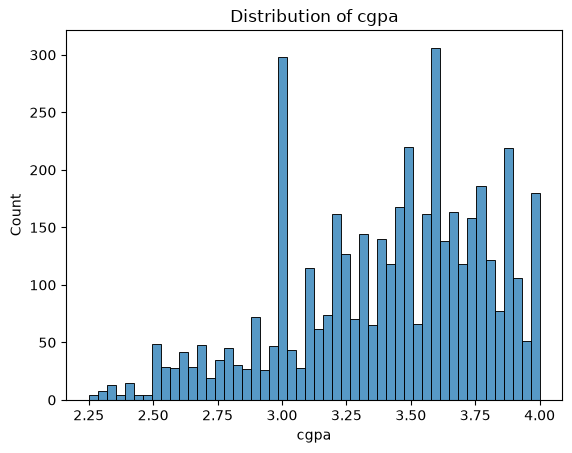

In [88]:
sns.histplot(df.cgpa, bins=50)
plt.title('Distribution of cgpa')
plt.show()

Left-skewed distribution, with noticeable spikes (probably due to the rounding)

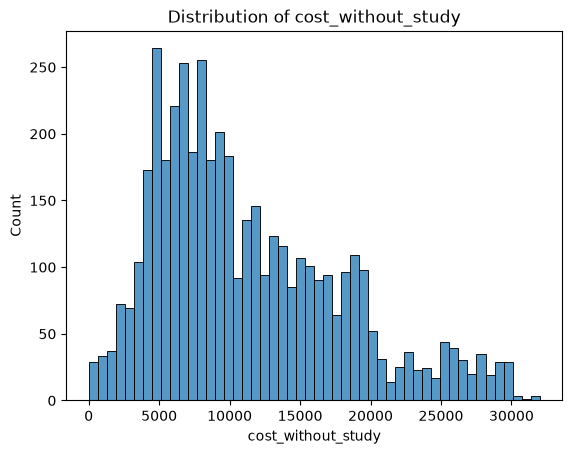

In [89]:
sns.histplot(df.cost_without_study, bins=50)
plt.title('Distribution of cost_without_study')
plt.show()

Right-skewed distribution with a long tail.

In [90]:
#applying np.log1p() to cost_without_study to reduce right-skewness
df['cost_without_study_log'] = np.log1p(df['cost_without_study'])
df_full_train['cost_without_study_log']=np.log1p(df_full_train['cost_without_study'])
df_train['cost_without_study_log'] = np.log1p(df_train['cost_without_study'])
df_val['cost_without_study_log'] = np.log1p(df_val['cost_without_study'])
df_test['cost_without_study_log'] = np.log1p(df_test['cost_without_study'])

In [91]:
#applying StandartScaler() to the numerical features
numerical=['age', 'cgpa', 'cost_without_study_log']
scaler = StandardScaler()

df_train[numerical] = scaler.fit_transform(df_train[numerical])
df_val[numerical] = scaler.transform(df_val[numerical])
df_test[numerical] = scaler.transform(df_test[numerical])

### Analysing the categorical features

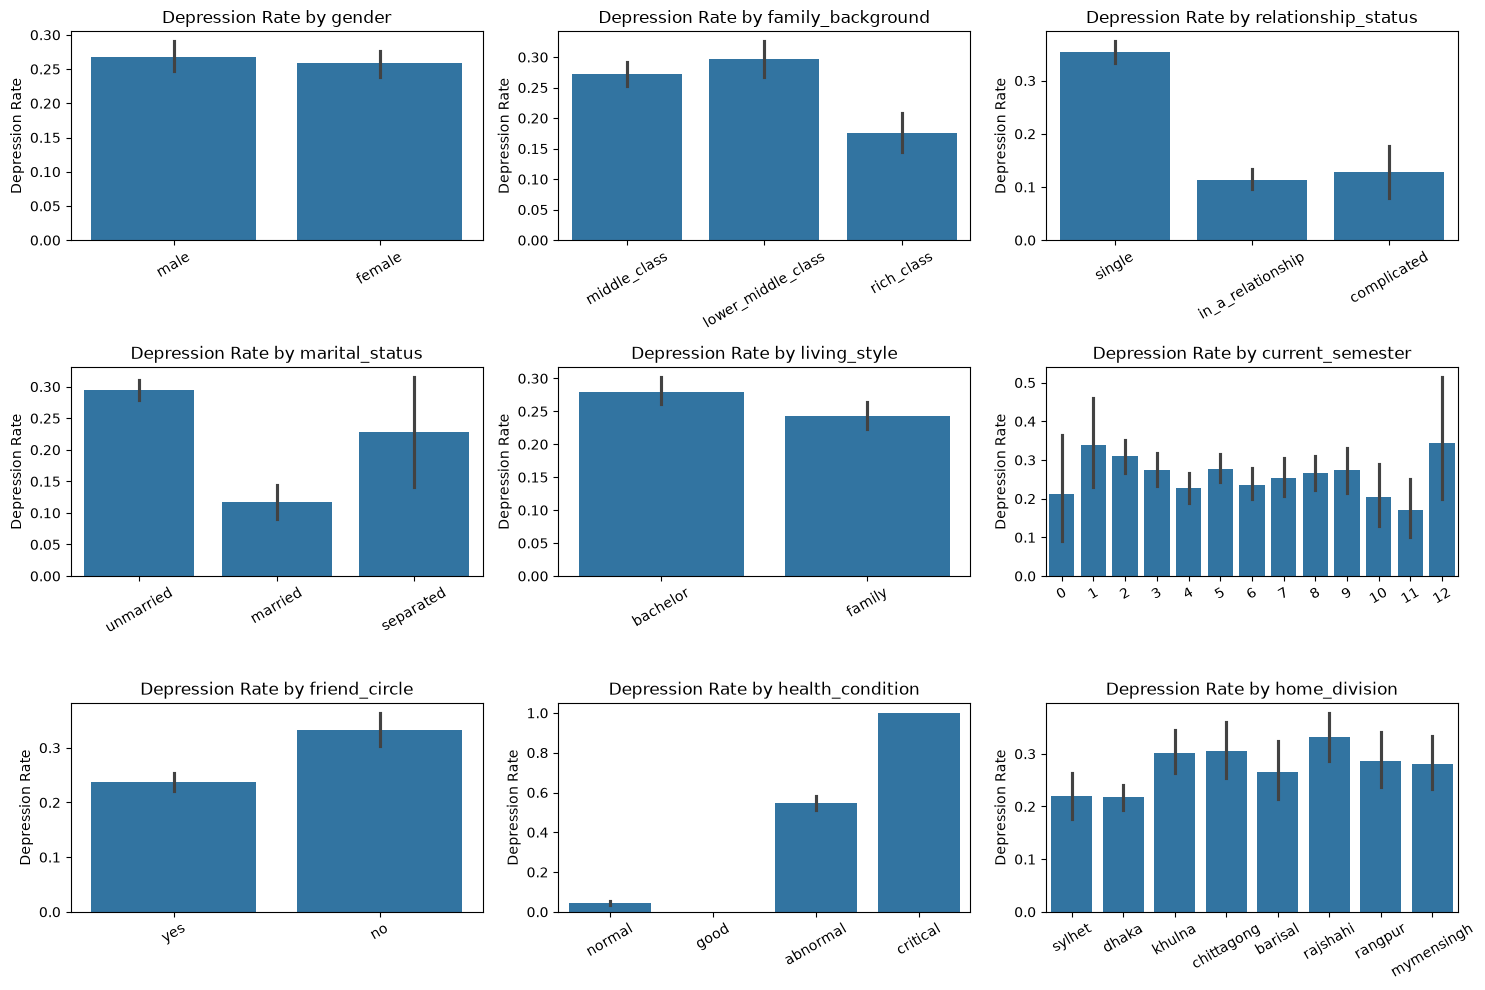

In [92]:
plt.figure(figsize=(15, 10))

for i, c in enumerate(categorical, 1):
    plt.subplot(3, 3, i)
    sns.barplot(x=c, y='depression', data=df_full_train)
    plt.title(f'Depression Rate by {c}')
    plt.ylabel('Depression Rate')
    plt.xlabel('')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Feature Importance

In [93]:
#mutual information (for categorical features)
def mutual_info_depression_score(series):
    return mutual_info_score(series, df_full_train.depression)

In [94]:
mi=df_full_train[categorical].apply(mutual_info_depression_score)
mi.sort_values(ascending=False)

health_condition       0.369738
relationship_status    0.037512
marital_status         0.012655
home_division          0.004635
friend_circle          0.004565
family_background      0.004176
current_semester       0.002859
living_style           0.000873
gender                 0.000050
dtype: float64

In [95]:
#correlation (for numerical features)
df_full_train[numerical].corrwith(df_full_train.depression)

age                      -0.045013
cgpa                     -0.083587
cost_without_study_log    0.034599
dtype: float64

## One-hot encoding

In [96]:
dicts=df[categorical+numerical].to_dict(orient='records')

In [97]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
test_dicts = df_test[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

## Baseline model

In [98]:
baseline_model= LogisticRegression(solver='liblinear', random_state=42)
baseline_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1

In [99]:
y_pred_prob=baseline_model.predict_proba(X_val)[:, 1]
baseline_auc = roc_auc_score(y_val, y_pred_prob)
print(f"Baseline Logistic Regression ROC-AUC: {baseline_auc:.4f}")

Baseline Logistic Regression ROC-AUC: 0.9889


## Logistic Regression model

In [100]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'l1_ratio': [0.0, 1.0],     # 0.0 λειτουργεί ως L2, 1.0 λειτουργεί ως L1
    'solver': ['saga']          # O saga είναι ο αλγόριθμος που υποστηρίζει το elasticnet
}

In [101]:
log_reg = LogisticRegression(max_iter=2000, random_state=42)

In [102]:
grid_search=GridSearchCV(estimator=log_reg, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...], 'l1_ratio': [0.0, 1.0], 'solver': ['saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity o

In [103]:
y_pred= grid_search.predict_proba(X_val)[:, 1]

val_auc = roc_auc_score(y_val, y_pred)

print(f"ROC-AUC on Validation Set: {val_auc:.4f}")

ROC-AUC on Validation Set: 0.9917
